# 46장 · 검색 개선 · 방향과 예시

45장의 Q03은 답할 문단이 있는데도 빈 결과를 냈습니다. 팀은 “실패”나 “오류”가 들어간 질문에서 p3을 찾는 검색 후보를 시험했습니다. 생성 함수와 입력 문서, k=2를 고정해 어떤 변화가 검색 정책 때문인지 읽습니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요.

## p3이 다시 검색되는지 확인하기

완성 실험 기록｜변경 전 Q03은 검색 1회, 빈 목록, 생성 0회입니다. 후보에서는 같은 문장에 오류 낱말을 인식해 p3을 가져옵니다. 여기서는 제공 기록에 맞춰 검색 조건 한 가지를 재현합니다.


### 셀 01 · 후보 규칙으로 업로드 오류 검색하기

Q03에 어떤 낱말이 들어 있으며 그 조건에서 어느 문단을 돌려주는지 확인하세요.

In [1]:
error_doc = {'id': 'course-guide-v1:p3',
 'text': '제출 오류가 발생하면 오류 화면과 발생 시간을 기록하고 담당 강사에게 문의합니다. 비밀키가 보이는 화면은 공유하지 '
         '않습니다.',
 'source': '가상 과정 운영 안내 · 45일 수업용 페이지판 (source-pages.html)',
 'page': 1}
question = '과제 업로드가 실패했어요. 어떻게 해야 하나요?'
found = [error_doc] if any(word in question for word in ('오류','실패')) else []
print([d['id'] for d in found])

['course-guide-v1:p3']


course-guide-v1:p3을 찾았습니다. 원문에는 오류 화면과 발생 시간 기록, 강사 문의, 비밀키 공유 금지가 담겨 있습니다.

## 검색이 고쳐져도 후보를 보류한 이유

고정 생성기는 Q01에서 썼던 p2를 인용합니다. 검색은 p3을 돌려주는데 p2 인용을 사용자에게 보여 주면 출처가 어긋납니다. 그래서 이번에는 기준선을 유지하고 생성 수정을 별도의 실험으로 넘깁니다.

<!-- motion:wrong-citation-pin -->
**p3을 찾았는데 왜 답을 보류할까요?**

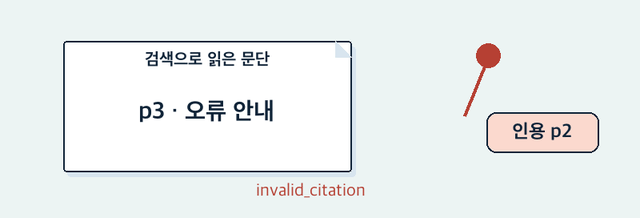

검색으로 가져온 문단은 p3입니다. 고정 생성기가 인용한 p2를 그 위에 맞춰 봐도 문단 번호가 일치하지 않습니다.
<!-- /motion -->


### 셀 02 · 변경 전후 기록의 마지막 상태 대조하기

두 행은 같은 Q03의 제공 로컬 실행 기록입니다. 검색 정책 외에 무엇을 고정했는지 기억하며 살펴보세요.

Q03에서 검색이 허용한 문단은 p3인데 고정 답변의 대괄호 안에는 p2가 있습니다. ‘검색 성공’에는 p3을, ‘인용 검사 실패’에는 p2를 적으세요. 검색 문서를 찾았다는 이유로 이 답을 사용자에게 내보내지 않습니다.

In [2]:
before = {'retrieved_ids': [],
 'result': {'status': 'no_evidence',
            'answer': '제공된 자료에서 확인할 수 없습니다.',
            'sources': [],
            'generation_calls': 0,
            'retrieved_ids': [],
            'seconds': 1e-06}}
after = {'retrieved_ids': ['course-guide-v1:p3'],
 'result': {'status': 'invalid_citation',
            'answer': '출처 표시를 확인해야 합니다.',
            'sources': [],
            'generation_calls': 1,
            'retrieved_ids': ['course-guide-v1:p3'],
            'seconds': 4e-06}}
print(before['retrieved_ids'], before['result']['status'])
print(after['retrieved_ids'], after['result']['status'])

[] no_evidence
['course-guide-v1:p3'] invalid_citation


빈 목록의 no_evidence가 p3과 invalid_citation으로 바뀌었습니다. 검색 성공과 사용자가 읽을 수 있는 답변 성공은 따로 기록해야 합니다. 자기 팀도 가장 자주 틀리는 단계 하나부터 비교하세요.

## 돌아보기

이 실험의 선택 후보는 error_keyword, 실제 유지한 방식은 baseline입니다. 다음 장을 맡은 팀원이 같은 조건에서 시작할 수 있도록 유지한 방식과 그 이유를 함께 건네세요.